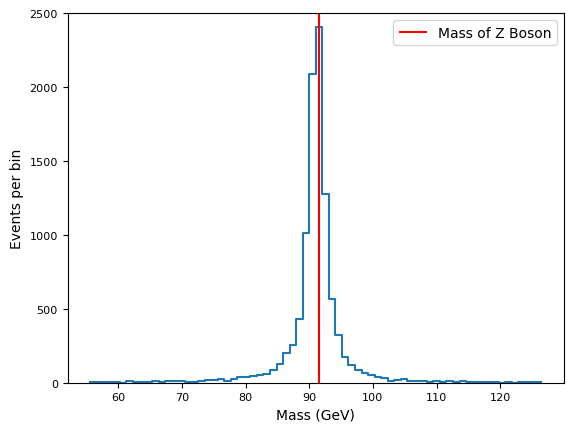

In [ ]:
import pythia8
import numpy as np
import matplotlib.pyplot as plt


file = pythia8.Pythia()
file.readString("Beams:frameType = 4") # Option 4 = Read LHE file
file.readString("Beams:LHEF = unweighted_events.lhe")
# file.readString("PartonLevel:all = off")
# file.readString("HadronLevel:all = off")
file.init()


E_tot, px_tot, py_tot, pz_tot=[],[],[],[]

while file.next():
    all_bquarks=[prt for prt in file.event if prt.idAbs() == 5 and 21 <= abs(prt.status()) <= 29]   #this list is created from the history of the final particle (b quarks decay further into mesons, muons)
    if len(all_bquarks)>=2:     #must have at least two bottom quarks in the event
        all_bquarks.sort(key=lambda particle: particle.pT(), reverse=True)
        E_tot.append(all_bquarks[0].e()+all_bquarks[1].e())
        px_tot.append(all_bquarks[0].px()+all_bquarks[1].px())
        py_tot.append(all_bquarks[0].py()+all_bquarks[1].py())
        pz_tot.append(all_bquarks[0].pz()+all_bquarks[1].pz())

E_tot=np.array(E_tot)
px_tot=np.array(px_tot)
py_tot=np.array(py_tot)
pz_tot=np.array(pz_tot)


m_Z= np.sqrt(E_tot**2-px_tot**2-py_tot**2-pz_tot**2)

histy, bin_edges = np.histogram(m_Z, bins=70)
bin_centers = 0.5*(bin_edges[1:] + bin_edges[:-1])
mass= bin_centers[np.argmax(histy)]
plt.plot(bin_centers,histy,drawstyle = 'steps-mid')
plt.vlines(mass, 0, 2500, colors='red', linestyles='solid', label='Mass of Z Boson')
plt.xlabel('Mass (GeV)', fontsize=10)
plt.ylabel('Events per bin', fontsize=10)
plt.ylim(0,2500) #Label y
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()



